# Deep Learning - Project 1

**Name:** `Robert-Constantin Bujor`

**NetID:** `rcb9438`

**Kaggle team:** `Robert Bujor`

## Results: a 4.5M-parameter Wide ResNet for CIFAR-10

**Final model:** WRN-28-3.5, a pre-activation Wide ResNet with **4,480,474 trainable parameters**
(limit 5,000,000). It was trained from scratch for 500 epochs on all 50,000 training images with
AutoAugment + Cutout and knowledge distillation from a 36.5M-parameter WRN-28-10 teacher, which is
only used during training.

**Final test accuracy (Kaggle, 2,000 hidden test images):** 0.896 public, 0.868 private.

This notebook does not train anything; training is done with `train.py` (see the README). It loads
the finished runs from `runs/`, prints the parameter count, re-checks the accuracies from the saved
weights, makes the figures used in the report and reproduces the final submission.

In [1]:
import io
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageFilter

from data import load_arrays
from models import CONFIGS, PARAM_LIMIT, build_model, count_params
from utils import (
    accuracy,
    device_name,
    get_device,
    load_trained_model,
    predict_logprobs,
)


RUNS = "runs"
FIGURES = "figures"
FINAL_RUN = "final_kd_wrn_aa_500"
CLASSES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]

# Kaggle scores, copied from the competition's submissions page because the
# test labels are hidden.
KAGGLE_PUBLIC = {
    "arch_wrn28_3.5": 0.858,
    "wrn_ta": 0.853,
    "wrn_aa": 0.860,
    "wrn_ta_mix": 0.840,
    "wrn_aa_200": 0.870,
    "final_wrn_aa_full": 0.888,
    "kd_wrn_aa_200": 0.885,
    "final_kd_wrn_aa_full": 0.895,
    "final_kd_wrn_aa_500": 0.896,
}
KAGGLE_PRIVATE = {"final_kd_wrn_aa_500": 0.868}


def model_path(run):
    # The full checkpoint from training if it is here, otherwise the compact
    # copy in checkpoints/.
    full_path = os.path.join(RUNS, run, "model.pt")

    if os.path.exists(full_path):
        return full_path

    return os.path.join("checkpoints", f"{run}.pt")


def read_log(run):
    return pd.read_csv(os.path.join(RUNS, run, "log.csv"))


device = get_device()
print("device:", device_name(device), "| torch", torch.__version__)

# The same 5,000-image validation split that was used in training.
(train_images, train_labels), (val_images, val_labels), (test_images, test_ids), (mean, std) = (
    load_arrays("data", val_size=5000, seed=0)
)
print(
    f"train {len(train_images)} | validation {len(val_images)} | "
    f"test {len(test_images)}"
)

os.makedirs(FIGURES, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

device: Apple GPU (MPS) | torch 2.8.0
train 45000 | validation 5000 | test 2000


## 1. Architecture and parameter count

All candidate networks are defined in `models.py`. The submitted model is `wrn28_3.5`: a 3×3 stem
convolution with 16 channels, three stages of four pre-activation residual blocks
(BN → ReLU → 3×3 conv → BN → ReLU → 3×3 conv, plus a skip connection) with 56, 112 and 224 channels,
global average pooling and a linear classifier. Stages 2 and 3 halve the resolution
(32 → 16 → 8) and use a 1×1 convolution on the skip path where the shape changes.

In [2]:
ROLES = {
    "wrn28_3.5": "submitted model",
    "wrn28_10": "teacher for distillation (not submitted)",
    "resnet18": "original ResNet-18, reference only (over the limit)",
}

final_net = build_model("wrn28_3.5")
n_params = count_params(final_net)
print(f"Number of trainable parameters (WRN-28-3.5): {n_params:,}")
print(f"Under the 5M limit: {n_params <= PARAM_LIMIT}")

rows = []

for name, config in CONFIGS.items():
    rows.append({
        "model": name,
        "block": config["block"],
        "channels per stage": config["widths"],
        "blocks per stage": config["depths"],
        "parameters": f"{count_params(build_model(name)):,}",
        "role": ROLES.get(name, "candidate"),
    })

pd.DataFrame(rows).set_index("model")

Number of trainable parameters (WRN-28-3.5): 4,480,474
Under the 5M limit: True


,block,channels per stage,blocks per stage,parameters,role
model,,,,,
resnet18_slim,basic,"(64, 128, 256, 224)","(2, 2, 2, 2)","4,707,786",candidate
resnet14_wide,basic,"(96, 192, 320)","(2, 2, 2)","4,902,506",candidate
wrn28_3.5,preact,"(56, 112, 224)","(4, 4, 4)","4,480,474",submitted model
wrn28_10,preact,"(160, 320, 640)","(4, 4, 4)","36,479,194",teacher for distillation (not submitted)
resnet18,basic,"(64, 128, 256, 512)","(2, 2, 2, 2)","11,173,962","original ResNet-18, reference only (over the l..."


In [3]:
# Parameters in each part of the final network.
parts = {
    "stem": final_net.stem,
    "stage 1 (56 ch, 32x32)": final_net.stages[0],
    "stage 2 (112 ch, 16x16)": final_net.stages[1],
    "stage 3 (224 ch, 8x8)": final_net.stages[2],
    "final BN": final_net.final_bn,
    "classifier": final_net.fc,
}
table = pd.DataFrame({
    "parameters": {name: count_params(part) for name, part in parts.items()}
})
table.loc["total"] = table["parameters"].sum()
display(table.style.format("{:,}"))

# The handout suggests torchsummary for checking the parameter count.
try:
    from torchsummary import summary
    summary(final_net, (3, 32, 32), device="cpu")
except ImportError:
    print("(torchsummary not installed: pip install torchsummary for the layer-by-layer table)")

,parameters
stem,432
"stage 1 (56 ch, 32x32)","207,344"
"stage 2 (112 ch, 16x16)","854,672"
"stage 3 (224 ch, 8x8)","3,415,328"
final BN,448
classifier,"2,250"
total,"4,480,474"


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 32, 32]             432
       BatchNorm2d-2           [-1, 16, 32, 32]              32
            Conv2d-3           [-1, 56, 32, 32]             896
            Conv2d-4           [-1, 56, 32, 32]           8,064
       BatchNorm2d-5           [-1, 56, 32, 32]             112
          Identity-6           [-1, 56, 32, 32]               0
            Conv2d-7           [-1, 56, 32, 32]          28,224
       PreActBlock-8           [-1, 56, 32, 32]               0
       BatchNorm2d-9           [-1, 56, 32, 32]             112
           Conv2d-10           [-1, 56, 32, 32]          28,224
      BatchNorm2d-11           [-1, 56, 32, 32]             112
         Identity-12           [-1, 56, 32, 32]               0
           Conv2d-13           [-1, 56, 32, 32]          28,224
      PreActBlock-14           [-1, 56,

## 2. All experiments

Validation accuracy is measured on 5,000 training images held out from training (500 per class),
with horizontal-flip test-time augmentation. Runs trained on all 50,000 images have no validation
number, so for them only the Kaggle score exists.

The first group of runs (architecture and augmentation comparisons) was trained in a Kaggle notebook
on T4 GPUs (`kaggle_notebook.ipynb`), and their numbers are copied from that notebook's output.
Everything else was trained on a MacBook Pro (Apple M5 Pro, PyTorch MPS) or a laptop RTX 4060 and is
loaded from `runs/` below.

In [4]:
AUG_NAMES = {
    "cutout": "cutout",
    "aa+cutout": "AutoAugment + cutout",
    "ta+cutout": "TrivialAugment + cutout",
}
LOCAL_RUNS = [
    "wrn_cutout_200",
    "teacher_wrn28_10",
    "kd_wrn_aa_200",
    "final_wrn_aa_full",
    "final_kd_wrn_aa_full",
    "final_kd_wrn_aa_500",
]
COLUMNS = [
    "run", "model", "params", "epochs", "train images", "augmentation", "teacher",
    "val acc", "Kaggle public", "Kaggle private", "minutes", "hardware",
]


def load_run(run):
    with open(os.path.join(RUNS, run, "config.json")) as file:
        config = json.load(file)

    with open(os.path.join(RUNS, run, "metrics.json")) as file:
        metrics = json.load(file)

    selected = metrics["selected"]
    n_train = 50000 if config["val_size"] == 0 else 50000 - config["val_size"]

    return {
        "run": run,
        "model": config["model"],
        "epochs": config["epochs"],
        "augmentation": AUG_NAMES.get(config["aug"], config["aug"]),
        "val acc": metrics.get(f"{selected}_val_acc_tta", np.nan),
        "minutes": metrics["minutes"],
        "train images": n_train,
        "teacher": "WRN-28-10" if config.get("teacher") else "",
        "hardware": config.get("gpu", ""),
    }


# Runs from the Kaggle notebook (T4 GPUs), copied from its output tables.
kaggle_notebook_runs = pd.DataFrame(
    [
        # run, model, epochs, augmentation, val acc, minutes
        ("baseline", "resnet18_slim", 30, "cutout", 0.9408, 9.2),
        ("arch_resnet18_slim", "resnet18_slim", 60, "cutout", 0.9558, 18.2),
        ("arch_resnet14_wide", "resnet14_wide", 60, "cutout", 0.9602, 20.7),
        ("arch_wrn28_3.5", "wrn28_3.5", 60, "cutout", 0.9624, 20.9),
        ("wrn_ta", "wrn28_3.5", 60, "TrivialAugment + cutout", 0.9568, 29.5),
        ("wrn_aa", "wrn28_3.5", 60, "AutoAugment + cutout", 0.9584, 31.6),
        ("wrn_ta_mix", "wrn28_3.5", 60, "TrivialAugment + cutout + mixup/CutMix", 0.9510, 29.1),
        ("wide_ta", "resnet14_wide", 60, "TrivialAugment + cutout", 0.9600, 28.3),
        ("wrn_aa_200", "wrn28_3.5", 200, "AutoAugment + cutout", np.nan, np.nan),
    ],
    columns=["run", "model", "epochs", "augmentation", "val acc", "minutes"],
)
kaggle_notebook_runs["train images"] = 45000
kaggle_notebook_runs["teacher"] = ""
kaggle_notebook_runs["hardware"] = "Kaggle T4"

local_runs = pd.DataFrame([
    load_run(run)
    for run in LOCAL_RUNS
    if os.path.exists(os.path.join(RUNS, run))
])

results = pd.concat([kaggle_notebook_runs, local_runs], ignore_index=True)
param_counts = {
    model: count_params(build_model(model))
    for model in results["model"].unique()
}
results["params"] = results["model"].map(param_counts)
results["Kaggle public"] = results["run"].map(KAGGLE_PUBLIC)
results["Kaggle private"] = results["run"].map(KAGGLE_PRIVATE)
results = results[COLUMNS]
results.to_csv(os.path.join(FIGURES, "all_results.csv"), index=False)

results.style.format(
    {
        "params": "{:,}",
        "val acc": "{:.2%}",
        "Kaggle public": "{:.3f}",
        "Kaggle private": "{:.3f}",
        "minutes": "{:.0f}",
    },
    na_rep="–",
)

,run,model,params,epochs,train images,augmentation,teacher,val acc,Kaggle public,Kaggle private,minutes,hardware
0,baseline,resnet18_slim,"4,707,786",30,45000,cutout,,94.08%,–,–,9,Kaggle T4
1,arch_resnet18_slim,resnet18_slim,"4,707,786",60,45000,cutout,,95.58%,–,–,18,Kaggle T4
2,arch_resnet14_wide,resnet14_wide,"4,902,506",60,45000,cutout,,96.02%,–,–,21,Kaggle T4
3,arch_wrn28_3.5,wrn28_3.5,"4,480,474",60,45000,cutout,,96.24%,0.858,–,21,Kaggle T4
4,wrn_ta,wrn28_3.5,"4,480,474",60,45000,TrivialAugment + cutout,,95.68%,0.853,–,30,Kaggle T4
5,wrn_aa,wrn28_3.5,"4,480,474",60,45000,AutoAugment + cutout,,95.84%,0.860,–,32,Kaggle T4
6,wrn_ta_mix,wrn28_3.5,"4,480,474",60,45000,TrivialAugment + cutout + mixup/CutMix,,95.10%,0.840,–,29,Kaggle T4
7,wide_ta,resnet14_wide,"4,902,506",60,45000,TrivialAugment + cutout,,96.00%,–,–,28,Kaggle T4
8,wrn_aa_200,wrn28_3.5,"4,480,474",200,45000,AutoAugment + cutout,,–,0.870,–,–,Kaggle T4
9,wrn_cutout_200,wrn28_3.5,"4,480,474",200,45000,cutout,,96.50%,–,–,171,Apple GPU (MPS)


## 3. Training curves

### 3.1 Short (60-epoch) comparisons from the Kaggle notebook

Architecture comparison, all with the same recipe (Cutout, 60 epochs):

![architecture comparison](figures/kaggle_arch_curves.png)

Augmentation comparison on WRN-28-3.5 (60 epochs). Stronger augmentation keeps the training loss much
higher, and at this short schedule it does not improve validation accuracy yet:

![augmentation comparison](figures/kaggle_aug60_curves.png)

### 3.2 Long runs, loaded from `runs/`

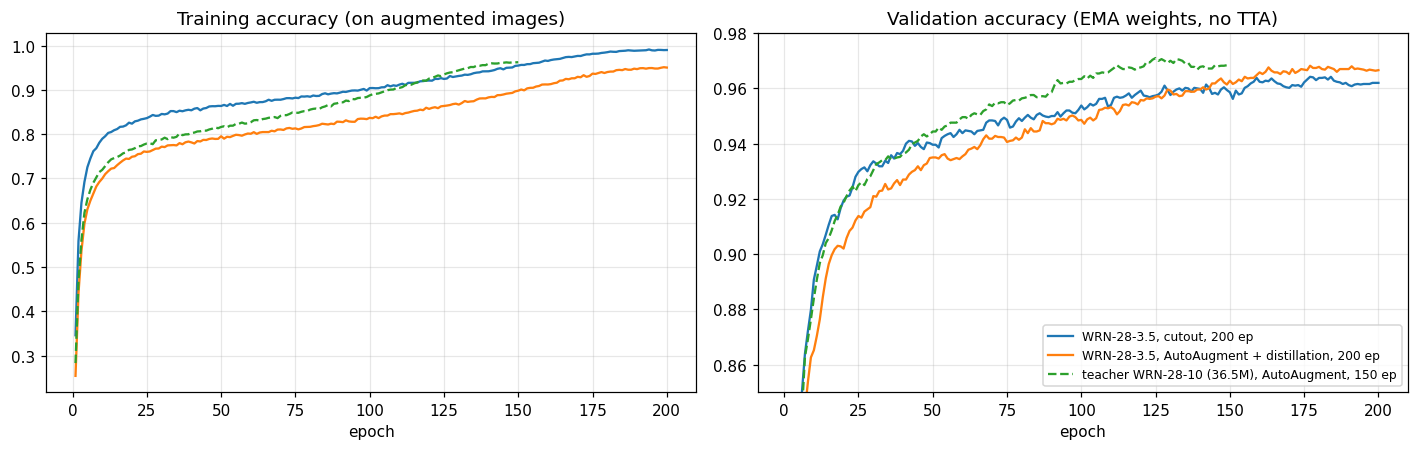

WRN-28-3.5, cutout, 200 ep                           final train acc 0.990 | best EMA val acc 0.9642
WRN-28-3.5, AutoAugment + distillation, 200 ep       final train acc 0.950 | best EMA val acc 0.9682
teacher WRN-28-10 (36.5M), AutoAugment, 150 ep       final train acc 0.962 | best EMA val acc 0.9710


In [5]:
LABELS = {
    "wrn_cutout_200": "WRN-28-3.5, cutout, 200 ep",
    "kd_wrn_aa_200": "WRN-28-3.5, AutoAugment + distillation, 200 ep",
    "teacher_wrn28_10": "teacher WRN-28-10 (36.5M), AutoAugment, 150 ep",
    "final_wrn_aa_full": "final, AutoAugment, 300 ep (50k images)",
    "final_kd_wrn_aa_full": "final, AutoAugment + distillation, 300 ep (50k)",
    "final_kd_wrn_aa_500": "final, AutoAugment + distillation, 500 ep (50k)",
}
VALIDATION_RUNS = ["wrn_cutout_200", "kd_wrn_aa_200", "teacher_wrn28_10"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

for run in VALIDATION_RUNS:
    log = read_log(run)
    style = "--" if run.startswith("teacher") else "-"
    axes[0].plot(log["epoch"], log["train_acc"], style, label=LABELS[run])
    axes[1].plot(log["epoch"], log["ema_val_acc"], style, label=LABELS[run])

axes[0].set(title="Training accuracy (on augmented images)", xlabel="epoch")
axes[1].set(
    title="Validation accuracy (EMA weights, no TTA)",
    xlabel="epoch",
    ylim=(0.85, 0.98),
)
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "long_runs_validation.png"), bbox_inches="tight")
plt.show()

for run in VALIDATION_RUNS:
    log = read_log(run)
    print(
        f"{LABELS[run]:52s} final train acc {log['train_acc'].iloc[-1]:.3f} | "
        f"best EMA val acc {log['ema_val_acc'].max():.4f}"
    )

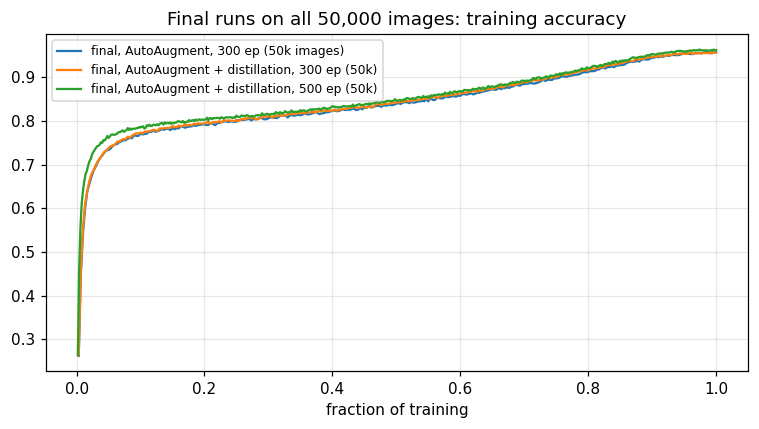

In [6]:
FINAL_RUNS = ["final_wrn_aa_full", "final_kd_wrn_aa_full", "final_kd_wrn_aa_500"]

fig, axis = plt.subplots(figsize=(7, 4))

# The runs have different lengths, so the x axis is the fraction of training.
for run in FINAL_RUNS:
    log = read_log(run)
    axis.plot(log["epoch"] / log["epoch"].max(), log["train_acc"], label=LABELS[run])

axis.set(
    title="Final runs on all 50,000 images: training accuracy",
    xlabel="fraction of training",
)
axis.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "final_runs_training.png"), bbox_inches="tight")
plt.show()

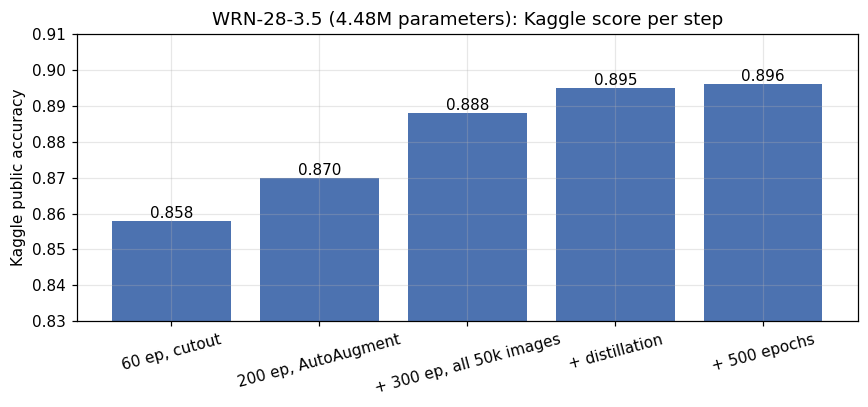

In [7]:
# Every step uses the same 4.48M-parameter network, so the bars show what
# each change to the training added on the public leaderboard.
STEPS = [
    ("60 ep, cutout", "arch_wrn28_3.5"),
    ("200 ep, AutoAugment", "wrn_aa_200"),
    ("+ 300 ep, all 50k images", "final_wrn_aa_full"),
    ("+ distillation", "final_kd_wrn_aa_full"),
    ("+ 500 epochs", "final_kd_wrn_aa_500"),
]

fig, axis = plt.subplots(figsize=(8, 3.8))
scores = [KAGGLE_PUBLIC[run] for _, run in STEPS]
bars = axis.bar([step for step, _ in STEPS], scores, color="#4C72B0")
axis.bar_label(bars, fmt="%.3f")
axis.set(
    ylim=(0.83, 0.91),
    ylabel="Kaggle public accuracy",
    title="WRN-28-3.5 (4.48M parameters): Kaggle score per step",
)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "kaggle_progression.png"), bbox_inches="tight")
plt.show()

### Discussion

**Architecture.** With the same 60-epoch Cutout recipe, WRN-28-3.5 reached 96.24% validation accuracy,
ahead of the wider ResNet-14 (96.02%) and the slimmed ResNet-18 (95.58%), while having the fewest
parameters (4.48M). All later runs use it.

**Augmentation needs long training.** At 60 epochs, AutoAugment (95.84%), TrivialAugment (95.68%) and
mixup/CutMix (95.10%) were all below plain Cutout, and the training accuracy stayed much lower, so the
network was still underfitting. Trained for 200 epochs, AutoAugment scored 0.870 on Kaggle against 0.858
for the 60-epoch Cutout run.

**More data, distillation and length.** Training on all 50,000 images for 300 epochs raised the public
score to 0.888, distilling from the WRN-28-10 teacher (97.40% validation accuracy) to 0.895, and 500
epochs to 0.896. With the validation split kept, distillation gave the best validation accuracy of any
4.5M-parameter run, 96.92%.

## 4. Re-checking validation accuracy from the saved weights

The distillation run `kd_wrn_aa_200` kept the 5,000 validation images out of training, so its accuracy
can be recomputed here from the saved weights.

In [8]:
kd_path = model_path("kd_wrn_aa_200")
kd_model, kd_checkpoint = load_trained_model(kd_path, device)
print(f"kd_wrn_aa_200: {count_params(kd_model):,} parameters (from {kd_path})")

# The full checkpoint holds both the raw and the EMA weights. The compact
# one only keeps the EMA weights that were used, stored as "raw".
if kd_checkpoint.get("ema_state_dict") is not None:
    variants = {"raw": "raw", "ema": "EMA"}
else:
    variants = {"raw": "EMA"}

for which, label in variants.items():
    model, _ = load_trained_model(kd_path, device, which=which)

    for tta in (False, True):
        logprobs = predict_logprobs(model, val_images, mean, std, device, tta=tta)
        tta_label = "flip TTA" if tta else "no TTA  "
        print(
            f"  {label:3s} weights, {tta_label}: "
            f"validation accuracy {accuracy(logprobs, val_labels):.4f}"
        )

val_logprobs = predict_logprobs(kd_model, val_images, mean, std, device, tta=True)
val_predictions = val_logprobs.argmax(1)

kd_wrn_aa_200: 4,480,474 parameters (from runs/kd_wrn_aa_200/model.pt)


  raw weights, no TTA  : validation accuracy 0.9670


  raw weights, flip TTA: validation accuracy 0.9690


  EMA weights, no TTA  : validation accuracy 0.9664


  EMA weights, flip TTA: validation accuracy 0.9694


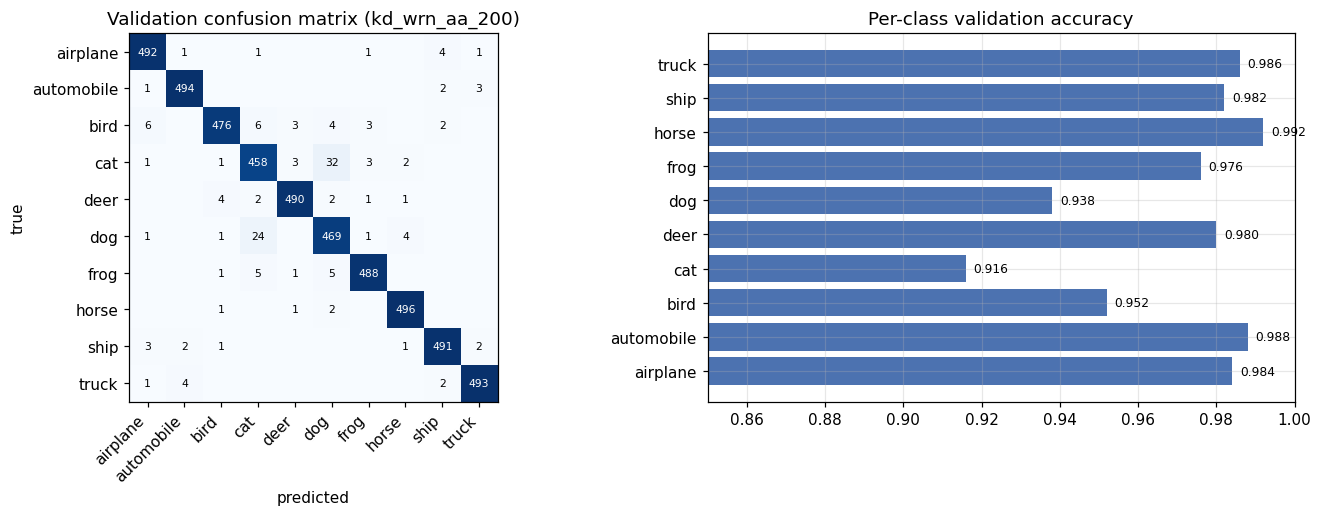

In [9]:
confusion = np.zeros((10, 10), dtype=int)

for true_label, predicted_label in zip(val_labels.tolist(), val_predictions.tolist()):
    confusion[true_label, predicted_label] += 1

fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.2, 1]}
)

axes[0].imshow(confusion, cmap="Blues")
axes[0].set(
    xticks=range(10),
    yticks=range(10),
    xlabel="predicted",
    ylabel="true",
    title="Validation confusion matrix (kd_wrn_aa_200)",
)
axes[0].set_xticklabels(CLASSES, rotation=45, ha="right")
axes[0].set_yticklabels(CLASSES)
axes[0].grid(False)

for row in range(10):
    for column in range(10):
        count = confusion[row, column]

        if count:
            axes[0].text(
                column,
                row,
                count,
                ha="center",
                va="center",
                fontsize=7,
                color="white" if count > 250 else "black",
            )

per_class = confusion.diagonal() / np.maximum(confusion.sum(1), 1)
axes[1].barh(CLASSES, per_class, color="#4C72B0")
axes[1].set(xlim=(0.85, 1.0), title="Per-class validation accuracy")

for index, value in enumerate(per_class):
    axes[1].text(value + 0.002, index, f"{value:.3f}", va="center", fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "confusion_matrix.png"), bbox_inches="tight")
plt.show()

### Discussion

Recomputed in float32, the EMA weights with flip TTA reach 96.94%, against the 96.92% logged at the end
of training. The small difference comes from the logged number being computed in bfloat16 on the RTX
4060. Flip TTA adds about 0.2-0.3 points to both the raw and the EMA weights. Cat and dog are the
weakest classes (91.6% and 93.8%), and confusions between the two make up 56 of the 153 errors.

## 5. Final model and test predictions

The final model was trained on all 50,000 images, so it has no validation number, and its test
accuracy comes from Kaggle because the test labels are hidden. Here the saved weights are loaded, the
2,000 test images are predicted again (with flip TTA) and compared with the submitted file.

In [10]:
final_model, final_checkpoint = load_trained_model(model_path(FINAL_RUN), device)
run_args = final_checkpoint["args"]
print(
    f"run: {FINAL_RUN} | model {final_checkpoint['model']} | "
    f"epochs {run_args['epochs']} | aug {run_args['aug']} | "
    f"teacher {run_args['teacher']} | weights {final_checkpoint['selected']}"
)

test_logprobs = predict_logprobs(final_model, test_images, mean, std, device, tta=True)
test_predictions = test_logprobs.argmax(1)

# Both sets of labels are compared in id order.
submitted = pd.read_csv(os.path.join(RUNS, FINAL_RUN, "submission.csv"))
submitted_labels = submitted.sort_values("id")["label"].to_numpy()
our_labels = test_predictions[np.argsort(test_ids.numpy())].numpy()
same = (submitted_labels == our_labels).mean()
print(f"predictions identical to the submitted file for {same:.1%} of test images")

final_submission = pd.DataFrame({
    "id": test_ids.numpy(),
    "label": test_predictions.numpy(),
})
final_submission.sort_values("id").to_csv("final_submission.csv", index=False)

class_counts = np.bincount(test_predictions.numpy(), minlength=10).tolist()
print("predicted class counts:", dict(zip(CLASSES, class_counts)))
print()
print(f"Number of trainable parameters: {count_params(final_model):,}")
print(
    f"Final test accuracy (Kaggle, hidden labels): "
    f"public {KAGGLE_PUBLIC[FINAL_RUN]:.3f}, private {KAGGLE_PRIVATE[FINAL_RUN]:.3f}"
)

run: final_kd_wrn_aa_500 | model wrn28_3.5 | epochs 500 | aug aa+cutout | teacher runs\teacher_wrn28_10\model.pt | weights ema


predictions identical to the submitted file for 100.0% of test images
predicted class counts: {'airplane': 180, 'automobile': 220, 'bird': 200, 'cat': 211, 'deer': 197, 'dog': 208, 'frog': 185, 'horse': 205, 'ship': 202, 'truck': 192}

Number of trainable parameters: 4,480,474
Final test accuracy (Kaggle, hidden labels): public 0.896, private 0.868


## 6. Why the test accuracy is about 10 points below validation

The models reach about 97% on held-out training images but about 87-90% on the Kaggle test set. This
section compares the two image sets without using any test labels.

In [11]:
def image_stats(images):
    pixels = images.float() / 255
    gray = pixels.mean(1)

    # A 3 x 3 box blur. What it removes is the high-frequency part.
    padded = torch.nn.functional.pad(
        gray[:, None], (1, 1, 1, 1), mode="replicate"
    )[:, 0]
    blurred = sum(
        padded[:, row:row + 32, column:column + 32]
        for row in range(3)
        for column in range(3)
    ) / 9
    extreme = (pixels <= 0.01) | (pixels >= 0.99)

    return {
        "brightness": gray.mean((1, 2)),
        "contrast": gray.std((1, 2)),
        "near-black/white pixels": extreme.float().mean((1, 2, 3)),
        "high-frequency energy": (gray - blurred).abs().mean((1, 2)),
    }


generator = torch.Generator().manual_seed(0)
sample = train_images[torch.randperm(len(train_images), generator=generator)[:10000]]
train_stats = image_stats(sample)
test_stats = image_stats(test_images)
rows = {}

for name in train_stats:
    for quantile in (0.5, 0.9):
        rows[(name, f"p{int(quantile * 100)}")] = {
            "training images": torch.quantile(train_stats[name], quantile).item(),
            "test images": torch.quantile(test_stats[name], quantile).item(),
        }

pd.DataFrame(rows).T.style.format("{:.4f}")

In [12]:
# How sensitive is the model to each kind of image change? Measured on
# 1,000 validation images without TTA.
def change_pixels(images, change):
    pixels = images.float() / 255
    return (change(pixels).clamp(0, 1) * 255).round().to(torch.uint8)


def change_with_pil(images, change):
    changed = [
        np.asarray(change(Image.fromarray(image)).convert("RGB"))
        for image in images.permute(0, 2, 3, 1).numpy()
    ]
    return torch.from_numpy(np.stack(changed)).permute(0, 3, 1, 2).contiguous()


def scale_around_mean(pixels, factor, dims):
    # Contrast scales each image around its mean, saturation scales each
    # pixel around its gray value.
    centre = pixels.mean(dims, keepdim=True)
    return (pixels - centre) * factor + centre


def add_noise(pixels):
    return pixels + 0.03 * torch.randn(pixels.shape, generator=generator)


def jpeg(image, quality=60):
    buffer = io.BytesIO()
    image.save(buffer, "JPEG", quality=quality)
    return Image.open(io.BytesIO(buffer.getvalue()))


def blur(image):
    return image.filter(ImageFilter.GaussianBlur(0.7))


generator = torch.Generator().manual_seed(0)

# The validation split is ordered by class, so a random subset is used.
subset = torch.randperm(len(val_images), generator=generator)[:1000]
subset_images, subset_labels = val_images[subset], val_labels[subset]

changes = {
    "none": lambda images: images,
    "brightness +0.2": lambda images: change_pixels(images, lambda pixels: pixels + 0.2),
    "contrast x1.3": lambda images: change_pixels(
        images, lambda pixels: scale_around_mean(pixels, 1.3, (1, 2, 3))
    ),
    "saturation x1.5": lambda images: change_pixels(
        images, lambda pixels: scale_around_mean(pixels, 1.5, 1)
    ),
    "Gaussian noise (sigma 0.03)": lambda images: change_pixels(images, add_noise),
    "blur (radius 0.7)": lambda images: change_with_pil(images, blur),
    "JPEG quality 60": lambda images: change_with_pil(images, jpeg),
}
sensitivity = {}

for name, change in changes.items():
    logprobs = predict_logprobs(
        kd_model, change(subset_images), mean, std, device, tta=False
    )
    sensitivity[name] = accuracy(logprobs, subset_labels)

pd.Series(sensitivity, name="validation accuracy").to_frame().style.format("{:.3f}")

,validation accuracy
none,0.967
brightness +0.2,0.967
contrast x1.3,0.967
saturation x1.5,0.969
Gaussian noise (sigma 0.03),0.916
blur (radius 0.7),0.947
JPEG quality 60,0.842


kd_wrn_aa_200 mean confidence: validation 0.890 | test 0.857
share of images with confidence < 0.6: validation 0.027 | test 0.076
test confidence by brightness quartile: [0.853, 0.853, 0.869, 0.854]
test confidence by contrast quartile: [0.853, 0.855, 0.86, 0.86]
test confidence by near-black/white pixels quartile: [0.859, 0.856, 0.857, 0.856]
test confidence by high-frequency energy quartile: [0.851, 0.862, 0.856, 0.86]


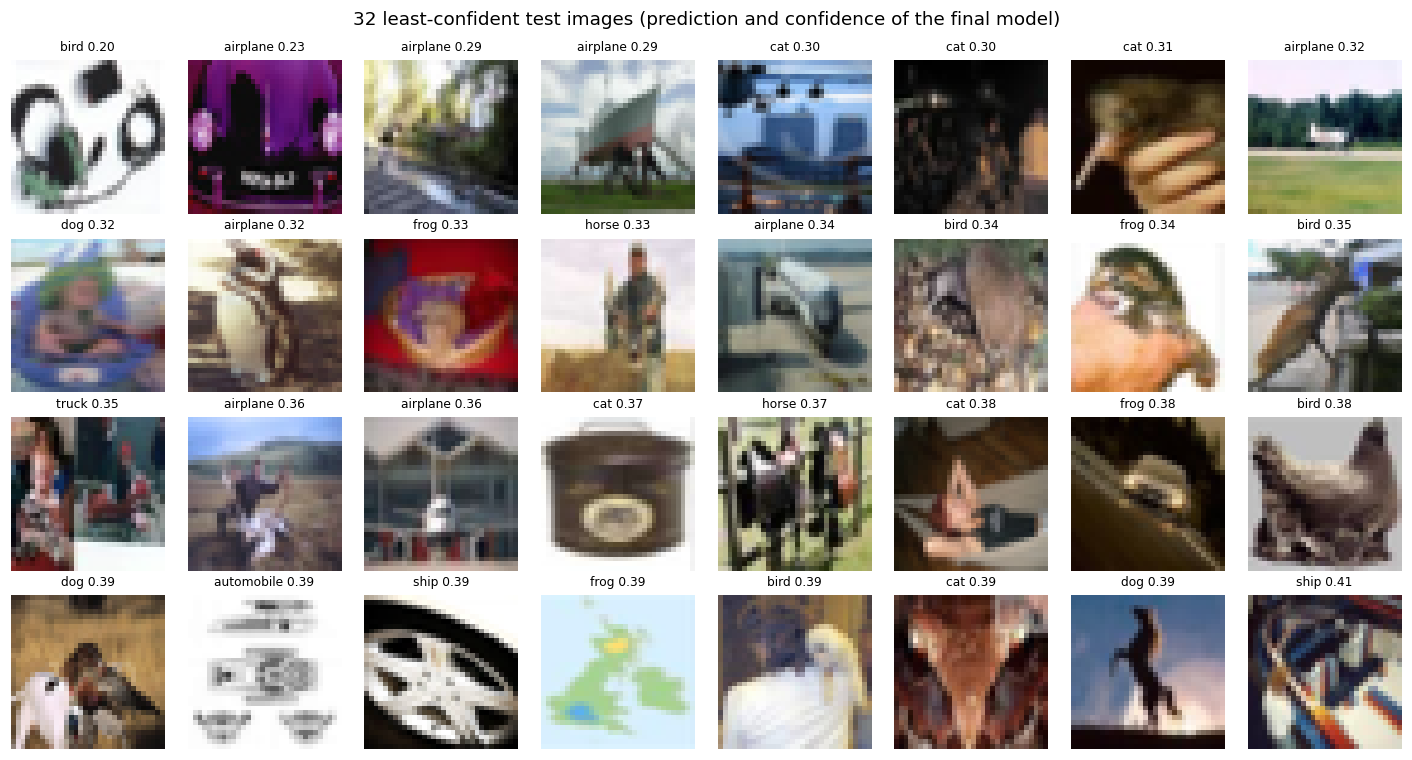

In [13]:
# Confidence on held-out validation images and on test images.
# kd_wrn_aa_200 never saw the validation images.
kd_val_confidence = val_logprobs.exp().max(1).values
kd_test_logprobs = predict_logprobs(kd_model, test_images, mean, std, device, tta=True)
kd_test_confidence = kd_test_logprobs.exp().max(1).values
print(
    f"kd_wrn_aa_200 mean confidence: validation {kd_val_confidence.mean():.3f} | "
    f"test {kd_test_confidence.mean():.3f}"
)
print(
    f"share of images with confidence < 0.6: "
    f"validation {(kd_val_confidence < 0.6).float().mean():.3f} | "
    f"test {(kd_test_confidence < 0.6).float().mean():.3f}"
)

# Does the confidence on test images depend on the image statistics above?
# The quartiles go from low to high.
for name, values in test_stats.items():
    edges = torch.quantile(values, torch.tensor([0.25, 0.5, 0.75]))
    quartile = torch.bucketize(values, edges)
    quartile_means = [
        round(kd_test_confidence[quartile == index].mean().item(), 3)
        for index in range(4)
    ]
    print(f"test confidence by {name} quartile:", quartile_means)

# The test images the final model is least sure about.
test_confidence = test_logprobs.exp().max(1).values
least_confident = torch.argsort(test_confidence)[:32]

fig, axes = plt.subplots(4, 8, figsize=(13, 7))

for axis, index in zip(axes.flat, least_confident.tolist()):
    axis.imshow(test_images[index].permute(1, 2, 0).numpy())
    axis.set_title(
        f"{CLASSES[test_predictions[index]]} {test_confidence[index]:.2f}",
        fontsize=8,
    )
    axis.axis("off")

plt.suptitle("32 least-confident test images (prediction and confidence of the final model)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "least_confident_test.png"), bbox_inches="tight")
plt.show()

### Discussion

**Image statistics.** The test images are brighter at the top end (90th percentile 0.692 against 0.632),
have more than twice as many near-black or near-white pixels at the 90th percentile (13.4% against 5.6%)
and slightly more high-frequency energy (median 0.037 against 0.033).

**Sensitivity.** Brightness, contrast and saturation changes do not affect the model (96.7-96.9%), while
noise (91.6%), blur (94.7%) and JPEG compression (84.2%) hurt it. Even so, no grain or compression
artefacts are visible in the test images, and the model's confidence on them does not depend on an
image's high-frequency energy, brightness or share of extreme pixels.

**Conclusion.** The model is less sure on the test images (mean confidence 0.857 against 0.890 on
validation), and the least-confident ones are unusual natural photos: people with animals or vehicles,
drawings, toys and unusual viewpoints. The test set therefore looks like a newly collected set of natural
images (similar to CIFAR-10.1 / CIFAR-10.2) rather than corrupted CIFAR-10 images, so the way to improve
the test score is to improve accuracy in general, which is what longer training, AutoAugment and
distillation did.

## 7. Compact checkpoints for the repository

`runs/*/model.pt` stores both the raw and the averaged (EMA) weights and is not in the repository. For
the repository only the weights that were actually used are kept (about 18 MB per model), in
`checkpoints/`. The cells above fall back to these files when `runs/*/model.pt` is missing, and
`predict.py` uses them to write a submission without training.

In [14]:
COMPACT_RUNS = ["kd_wrn_aa_200", FINAL_RUN]
os.makedirs("checkpoints", exist_ok=True)

for run in COMPACT_RUNS:
    full_path = os.path.join(RUNS, run, "model.pt")

    if not os.path.exists(full_path):
        print(f"{run}: compact checkpoint already in checkpoints/ (no full checkpoint here)")
        continue

    checkpoint = torch.load(full_path, map_location="cpu", weights_only=False)
    use_ema = checkpoint["selected"] == "ema"

    # Only the weights used for the predictions are kept. They are stored
    # as "raw", so load_trained_model picks them by default.
    compact = {
        "model": checkpoint["model"],
        "model_overrides": checkpoint.get("model_overrides", {}),
        "args": checkpoint["args"],
        "metrics": checkpoint.get("metrics", {}),
        "selected": "raw",
        "state_dict": checkpoint["ema_state_dict"] if use_ema else checkpoint["state_dict"],
        "ema_state_dict": None,
    }
    compact_path = os.path.join("checkpoints", f"{run}.pt")
    torch.save(compact, compact_path)
    print(
        f"saved {compact_path} ({os.path.getsize(compact_path) / 1e6:.1f} MB, "
        f"{checkpoint['selected']} weights)"
    )

compact_model, _ = load_trained_model(os.path.join("checkpoints", f"{FINAL_RUN}.pt"), device)
compact_predictions = predict_logprobs(
    compact_model, test_images, mean, std, device, tta=True
).argmax(1)
same = (compact_predictions == test_predictions).float().mean()
print(
    f"compact final checkpoint: {count_params(compact_model):,} parameters, "
    f"predictions identical to the submission for {same:.1%} of test images"
)

saved checkpoints/kd_wrn_aa_200.pt (18.0 MB, ema weights)
saved checkpoints/final_kd_wrn_aa_500.pt (18.0 MB, ema weights)


compact final checkpoint: 4,480,474 parameters, predictions identical to the submission for 100.0% of test images
